POTATO LEAF DISEASE DETECTION USING NEURAL NETS

In [ ]:
#pip install opencv-python

Note: you may need to restart the kernel to use updated packages.


In [1]:
# importing neccessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

import os
import cv2

In [2]:
#function to load images from folder

def load_img_from_folder(base_folder, img_size=(128,128)):
    data =[]
    for label in os.listdir(base_folder):   #early_blight / late_blight / healthy
        label_folder = os.path.join(base_folder,label)
        if not os.path.isdir(label_folder):
            continue
        for filename in os.listdir(label_folder):
            file_path = os.path.join(label_folder,filename)
            img = cv2.imread(file_path)
            if img is not None:
                img = cv2.resize(img,img_size)  #resize for consistency
                data.append((img,label))
    return data

In [3]:
#paths to all dataset - train / test / validation
test_path = "/Users/partha/AI_ML_Projects/Leaf-Disease-Detection-Neural-Nets/dataset/PLD_3_Classes_256/Testing"
train_path = "/Users/partha/AI_ML_Projects/Leaf-Disease-Detection-Neural-Nets/dataset/PLD_3_Classes_256/Training"
val_path = "/Users/partha/AI_ML_Projects/Leaf-Disease-Detection-Neural-Nets/dataset/PLD_3_Classes_256/Validation"

#load data using function above:
test_data = load_img_from_folder(test_path)
train_data = load_img_from_folder(train_path)
val_data = load_img_from_folder(val_path)

In [4]:
#lets combine the dataset
all_data = test_data + train_data + val_data

#create a dataframe
df = pd.DataFrame(all_data, columns=["image","label"])


In [5]:
print('Total Samples: ', len(df) ) ## 4072

Total Samples:  4072


In [6]:
row = df.iloc[0]
img = row["image"]

#Shape of image:
print("Shape of image: ", img.shape)    #Shape of image:  (128, 128, 3)
print("Size of image: ", img.size)      #Size of image:  49152

df["image"] = df["image"].apply(lambda img: cv2.resize(img,(224,224)))
print("New Shape: ", df.iloc[0]["image"].shape)     #New Shape:  (224, 224, 3)

Shape of image:  (128, 128, 3)
Size of image:  49152
New Shape:  (224, 224, 3)


In [7]:
#Train-Test Split
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

print(train_df.shape)   #(3257, 2)
print(test_df.shape)    #(815, 2)

train_images = train_df["image"]
train_labels = train_df["label"]
test_images = test_df["image"]
test_labels = test_df["label"]

train_images = np.stack(train_images)
test_images = np.stack(test_images)

(3257, 2)
(815, 2)


In [8]:
#reshaping the train and test images:
train_images = train_images.reshape(train_images.shape[0],224,224,3)
test_images = test_images.reshape(test_images.shape[0],224,224,3)

train_images = train_images/255
test_images = test_images/255

train_images = train_images.astype("float32")
test_images = test_images.astype("float32")

In [ ]:
#pip install "numpy==1.23.5" "opencv-python<4.10"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.4/13.4 MB 3.7 MB/s  0:00:03m 3.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.4/35.4 MB 4.1 MB/s  0:00:08a 0:00:01m eta 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
  Attempting uninstall: opencv-python━━━━━━━━━━━━━━━━━ 0/2 [numpy]
    Found existing installation: opencv-python 5.1.0.950/2 [numpy]
    Uninstalling opencv-python-5.1.0.95:━━━━━━━━━━ 0/2 [numpy]
      Successfully uninstalled opencv-python-5.1.0.95m 0/2 [numpy]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [opencv-python]m 1/2 [opencv-python]
Note: you may need to restart the kernel to use updated packages.


In [9]:
#label encoder to labels:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
train_labels = le.fit_transform(train_labels)
test_labels = le.transform(test_labels)

#categorical labels:
import tensorflow
from tensorflow.keras.utils import to_categorical
train_labels = to_categorical(train_labels)
test_labels = to_categorical(test_labels)

[1. 0. 0.]
Sample:10 Label:[1. 0. 0.]


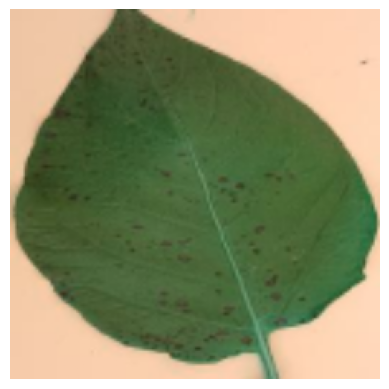

In [11]:
#Display the image:
def display_img(num):
    print(train_labels[num])
    image = train_images[num]
    print(f"Sample:{num} Label:{train_labels[num]}")
    plt.imshow(image)
    plt.axis('off')
    plt.show()

display_img(10)